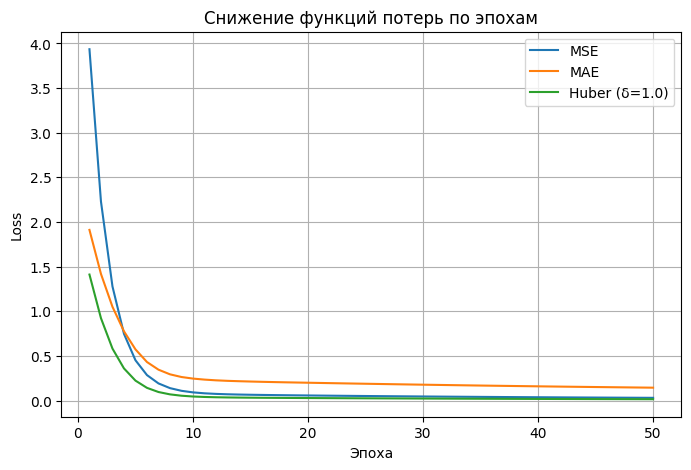

In [1]:
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(0)
X = np.linspace(0, 1, 100)[:, None]  # (100,1)
Y = 2 * X + 1 + np.random.randn(100, 1) * 0.1  # шумные точки


class MLP:
    def __init__(self, layer_sizes, activation="tanh"):
        self.layer_sizes = layer_sizes
        self.activation = activation
        self.W, self.b = [], []
        self.Z_list, self.A_list = [], []
        self.dW_list, self.db_list = [], []
        for i in range(len(layer_sizes) - 1):
            in_dim, out_dim = layer_sizes[i], layer_sizes[i + 1]
            self.W.append(np.random.randn(in_dim, out_dim) * 0.1)
            self.b.append(np.zeros((1, out_dim)))

    def _activate(self, Z):
        if self.activation == "sigmoid":
            return 1 / (1 + np.exp(-Z))
        elif self.activation == "relu":
            return np.maximum(0, Z)
        elif self.activation == "tanh":
            return np.tanh(Z)
        else:
            raise ValueError(self.activation)

    def _dactivate(self, Z):
        if self.activation == "sigmoid":
            s = 1 / (1 + np.exp(-Z))
            return s * (1 - s)
        elif self.activation == "relu":
            return (Z > 0).astype(float)
        elif self.activation == "tanh":
            return 1 - np.tanh(Z) ** 2

    def forward(self, X):
        self.Z_list, self.A_list = [], []
        A = X
        self.A_list.append(A)
        for i in range(len(self.W)):
            Z = A.dot(self.W[i]) + self.b[i]
            self.Z_list.append(Z)
            A = self._activate(Z) if i < len(self.W) - 1 else Z
            self.A_list.append(A)
        return A

    def mse(self, y_pred, y_true):
        return np.mean((y_pred - y_true) ** 2)

    def backward(self, y_true):
        m = y_true.shape[0]
        # выходной слой
        aL, zL = self.A_list[-1], self.Z_list[-1]
        delta = 2 * (aL - y_true) / m
        # градиенты выхода
        a_prev = self.A_list[-2]
        dW = a_prev.T.dot(delta)
        db = np.sum(delta, axis=0, keepdims=True)
        self.dW_list, self.db_list = [dW], [db]
        # скрытые
        for l in range(len(self.layer_sizes) - 2, 0, -1):
            z = self.Z_list[l - 1]
            a_prev = self.A_list[l - 1]
            W_next = self.W[l]
            delta = delta.dot(W_next.T) * self._dactivate(z)
            dW = a_prev.T.dot(delta)
            db = np.sum(delta, axis=0, keepdims=True)
            self.dW_list.insert(0, dW)
            self.db_list.insert(0, db)

    def update_params(self, lr):
        # Обновляем веса и смещения
        for i in range(len(self.W)):
            # Обновляем веса W и смещения b.
            #  W[i] -= lr * dW_list[i]
            # Ваш код здесь
            #  b[i] -= lr * db_list[i]
            self.W[i] -= lr * self.dW_list[i]
            self.b[i] -= lr * self.db_list[i]


def mse(y, y_pred):
    # Ваш код здесь
    return np.mean((y - y_pred) ** 2)


def mae(y, y_pred):
    # Ваш код здесь
    return np.mean(np.abs(y - y_pred))


def huber(y, y_pred, delta=5):
    # Ваш код здесь
    diff = y - y_pred
    small = np.abs(diff) <= delta
    squared = 0.5 * diff**2
    linear = delta * (np.abs(diff) - 0.5 * delta)
    return np.mean(np.where(small, squared, linear))


np.random.seed(0)
X = np.linspace(0, 1, 100)[:, None]
# Создаём линейную зависимость с шумом в виде np.random.randn(100,1)*0.1
Y = 2 * X + 1 + np.random.randn(100, 1) * 0.1


model = MLP([1, 1], activation="tanh")
lr, epochs = 0.1, 50


# Истории для трёх loss
loss_mse, loss_mae, loss_huber = [], [], []

for epoch in range(1, epochs + 1):
    preds = model.forward(X)

    # Считаем все три loss
    loss_mse.append(model.mse(preds, Y))
    loss_mae.append(np.mean(np.abs(preds - Y)))
    loss_huber.append(huber(preds, Y, delta=1.0))  # увеличили delta

    # Обучение
    model.backward(Y)
    model.update_params(lr)

# Визуализация
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), loss_mse, label="MSE")
plt.plot(range(1, epochs + 1), loss_mae, label="MAE")
plt.plot(range(1, epochs + 1), loss_huber, label="Huber (δ=1.0)")
plt.title("Снижение функций потерь по эпохам")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

Epoch 500: new lr = 0.05000
Epoch 1000: new lr = 0.02500
Epoch 1500: new lr = 0.01250
Epoch 2000: new lr = 0.00625
Epoch 2500: new lr = 0.00313
Epoch 3000: new lr = 0.00156
Epoch 3500: new lr = 0.00078
Epoch 4000: new lr = 0.00039
Epoch 4500: new lr = 0.00020
Epoch 5000: new lr = 0.00010


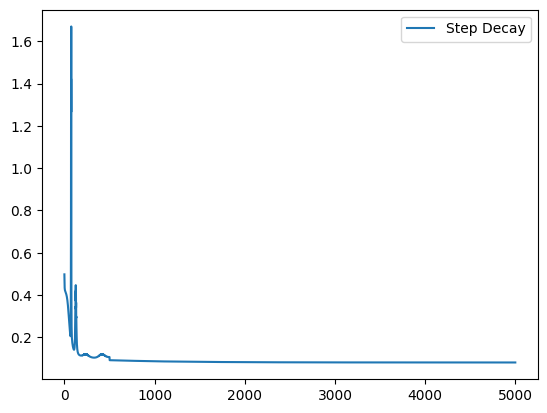

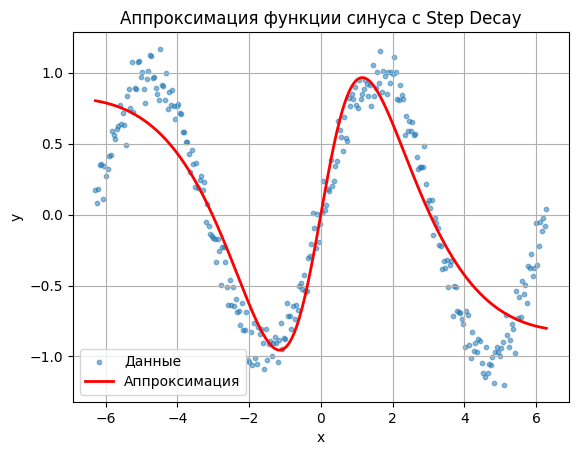

In [3]:
# Что нужно сделать

# Во время обучения фиксированный learning rate может оказывать разный эффект на разных этапах: сперва нужны крупные шаги для быстрого спуска, а ближе к концу — более мелкие. В этом задании вы реализуете step decay — уменьшение lr вдвое каждые $k$ эпох.
# Инициализируйте модель MLP с 50 скрытыми нейронами и tanh-активацией.
# Обучите модель на синусоиде с помощью step decay.
# Пусть изначальный learning rate будет равен 0.01, $k=500$, decay factor — 0.5.
# Обучайте модель в течение 5000 эпох.
# Сохраняйте значения функции потерь в списке loss_history.
# После обучения визуализируйте кривую обучения и сравните её с истинной синусоидой.


# Сгенерируем синтетические данные
np.random.seed(0)
X = np.linspace(-2 * np.pi, 2 * np.pi, 300)[:, None]
y = np.sin(X) + 0.1 * np.random.randn(*X.shape)

mlp = MLP([1, 50, 1], activation="tanh")

# Инициализация параметров обучения
initial_lr = 0.1  # Ваш код здесь
lr = initial_lr
k = 500  # Ваш код здесь
decay_factor = 0.5  # Ваш код здесь
epochs = 5000  # Ваш код здесь
loss_history = []

for epoch in range(1, epochs + 1):
    # обучаем полный проход
    preds = mlp.forward(X)
    loss = mlp.mse(preds, y)
    loss_history.append(loss)
    mlp.backward(y)
    mlp.update_params(lr)

    if epoch % k == 0:
        # Нужно сделать уменьшение lr каждые k эпох
        # Ваш код здесь
        lr *= decay_factor

        # напечатаем значение lr для конкретного k
        print(f"Epoch {epoch}: new lr = {lr:.5f}")

# Визуализация
plt.plot(loss_history, label="Step Decay")
plt.legend()
plt.show()

# После обучения
preds = mlp.forward(X)
idx = np.argsort(X.flatten())
X_sorted = X.flatten()[idx]
preds_sorted = preds.flatten()[idx]

plt.scatter(X, y, s=10, alpha=0.5, label="Данные")
plt.plot(X_sorted, preds_sorted, color="red", linewidth=2, label="Аппроксимация")
plt.title("Аппроксимация функции синуса с Step Decay")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

  → Plateau reached. New lr = 0.00500
  → Plateau reached. New lr = 0.00250
  → Plateau reached. New lr = 0.00125
  → Plateau reached. New lr = 0.00063
Epoch 200: train_loss=0.4319, val_loss=0.4049, lr=0.00063
Epoch 400: train_loss=0.4298, val_loss=0.4039, lr=0.00063
Epoch 600: train_loss=0.4278, val_loss=0.4027, lr=0.00063
Epoch 800: train_loss=0.4259, val_loss=0.4013, lr=0.00063
Epoch 1000: train_loss=0.4240, val_loss=0.3998, lr=0.00063
Epoch 1200: train_loss=0.4222, val_loss=0.3983, lr=0.00063
Epoch 1400: train_loss=0.4204, val_loss=0.3966, lr=0.00063
Epoch 1600: train_loss=0.4185, val_loss=0.3949, lr=0.00063
Epoch 1800: train_loss=0.4166, val_loss=0.3930, lr=0.00063
Epoch 2000: train_loss=0.4146, val_loss=0.3911, lr=0.00063
Epoch 2200: train_loss=0.4125, val_loss=0.3890, lr=0.00063
Epoch 2400: train_loss=0.4102, val_loss=0.3868, lr=0.00063
Epoch 2600: train_loss=0.4078, val_loss=0.3843, lr=0.00063
Epoch 2800: train_loss=0.4051, val_loss=0.3817, lr=0.00063
Epoch 3000: train_loss=0.4

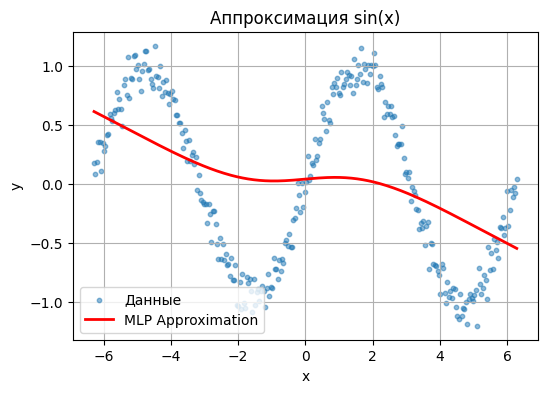

In [ ]:
# Что нужно сделать

# Когда на валидации потери перестают уменьшаться (попадаем на «плато»), имеет смысл уменьшить lr, чтобы добиться снижения функции потерь. Реализуйте Reduce on Plateau: если валидационная loss не улучшилась patience эпох подряд, делите lr на 2 и сбрасывайте счётчик.

# Разбиваем на train/val
perm = np.random.permutation(len(X))
split = int(0.8 * len(X))
X_train, y_train = X[perm[:split]], y[perm[:split]]
X_val, y_val = X[perm[split:]], y[perm[split:]]

# Инициализация модели
mlp = MLP([1, 50, 1], activation="tanh")

# Параметры обучения и Reduce on Plateau
initial_lr = 0.01
lr = initial_lr
patience = 20  # patience отвечает за количество эпох, в течение которых валидационная loss не улучшается
best_val_loss = np.inf  # инициализируем лучшую валидационную loss
wait = 0  # счётчик эпох без улучшения
epochs = 5000

train_loss_history = []
val_loss_history = []

for epoch in range(1, epochs + 1):
    # тренировка на всём train
    preds_train = mlp.forward(X_train)
    train_loss = mlp.mse(preds_train, y_train)
    train_loss_history.append(train_loss)

    mlp.backward(y_train)
    mlp.update_params(lr)

    # оценка на валидации
    preds_val = mlp.forward(X_val)
    val_loss = mlp.mse(preds_val, y_val)
    val_loss_history.append(val_loss)

    # Реализуйте Reduce on Plateau
    # Ваш код здесь

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        wait = 0
    else:
        wait += 1
        if wait >= patience:
            lr *= 0.5
            wait = 0
            print(f"  → Plateau reached. New lr = {lr:.5f}")

    if epoch % 200 == 0:
        print(
            f"Epoch {epoch}: train_loss={train_loss:.4f}, val_loss={val_loss:.4f}, lr={lr:.5f}"
        )

# График финальной аппроксимации
preds_all = mlp.forward(X)
idx = np.argsort(X.flatten())
plt.figure(figsize=(6, 4))
plt.scatter(X, y, s=10, alpha=0.5, label="Данные")
plt.plot(
    X.flatten()[idx],
    preds_all.flatten()[idx],
    color="red",
    linewidth=2,
    label="MLP Approximation",
)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Аппроксимация sin(x)")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Что нужно сделать

# Адаптивный оптимизатор AdaGrad масштабирует шаг для каждого параметра на основании накопленной суммы квадратов его градиентов. Это позволяет уменьшать lr там, где градиенты большие и частые.
# Реализуйте метод update_adagrad в классе MLP:
# Введите маленькую константу eps для избежания деления на ноль.
# Инициализируйте накопители квадратов градиентов GW и Gb нулями.
# Обновите веса и смещения с помощью адаптивного шага — повторите предыдущий запуск с Reduce on Plateau, но теперь используйте update_adagrad вместо update_params.
# Сравните качество аппроксимации этого метода и предыдущих.

import matplotlib.pyplot as plt
import numpy as np

np.random.seed(0)


class MLP:
    def __init__(self, layer_sizes, activation="tanh"):
        # Маленькая константа для избежания деления на ноль
        # Ваш код здесь
        self.layer_sizes = layer_sizes
        self.activation = activation
        self.W, self.b = [], []
        self.Z_list, self.A_list = [], []
        self.dW_list, self.db_list = [], []
        # Добавим накопители квадратов градиентов
        # Ваш код здесь
        self.GW, self.Gb = [], []

        for i in range(len(layer_sizes) - 1):
            in_dim, out_dim = layer_sizes[i], layer_sizes[i + 1]
            self.W.append(
                np.random.randn(in_dim, out_dim) * np.sqrt(2 / (in_dim + out_dim))
            )
            self.b.append(np.zeros((1, out_dim)))
            # Инициализация накопителей нулями
            # Ваш код здесь
            self.GW.append(np.zeros((in_dim, out_dim)))
            self.Gb.append(np.zeros((1, out_dim)))

    def _activate(self, Z):
        if self.activation == "sigmoid":
            return 1 / (1 + np.exp(-Z))
        elif self.activation == "relu":
            return np.maximum(0, Z)
        elif self.activation == "tanh":
            return np.tanh(Z)
        else:
            raise ValueError(self.activation)

    def _dactivate(self, Z):
        if self.activation == "sigmoid":
            s = 1 / (1 + np.exp(-Z))
            return s * (1 - s)
        elif self.activation == "relu":
            return (Z > 0).astype(float)
        elif self.activation == "tanh":
            return 1 - np.tanh(Z) ** 2

    def forward(self, X):
        self.Z_list, self.A_list = [], []
        A = X
        self.A_list.append(A)
        for i in range(len(self.W)):
            Z = A.dot(self.W[i]) + self.b[i]
            self.Z_list.append(Z)
            A = self._activate(Z) if i < len(self.W) - 1 else Z
            self.A_list.append(A)
        return A

    def mse(self, y_pred, y_true):
        return np.mean((y_pred - y_true) ** 2)

    def backward(self, y_true):
        m = y_true.shape[0]
        # Выходной слой (линейная активация, производная = 1)
        aL, zL = self.A_list[-1], self.Z_list[-1]
        delta = 2 * (aL - y_true) / m
        # Градиенты выхода
        a_prev = self.A_list[-2]
        dW = a_prev.T.dot(delta)
        db = np.sum(delta, axis=0, keepdims=True)
        self.dW_list, self.db_list = [dW], [db]
        # Скрытые слои (используем производную активации)
        for l in range(len(self.layer_sizes) - 2, 0, -1):
            z = self.Z_list[l - 1]
            a_prev = self.A_list[l - 1]
            W_next = self.W[l]
            delta = delta.dot(W_next.T) * self._dactivate(z)
            dW = a_prev.T.dot(delta)
            db = np.sum(delta, axis=0, keepdims=True)
            self.dW_list.insert(0, dW)
            self.db_list.insert(0, db)

    def update_adagrad(self, lr):
        # Обновляем веса и смещения с помощью Adagrad
        # Ваш код здесь
        eps = 1e-8  # Маленькая константа для избежания деления на ноль
        for i in range(len(self.W)):
            # Обновляем накопители квадратов градиентов
            self.GW[i] += self.dW_list[i] ** 2
            self.Gb[i] += self.db_list[i] ** 2

            # Адаптивный шаг для каждого параметра
            adapted_lr_W = lr / (np.sqrt(self.GW[i]) + eps)
            adapted_lr_b = lr / (np.sqrt(self.Gb[i]) + eps)

            # Обновляем веса и смещения с использованием адаптивного шага
            self.W[i] -= adapted_lr_W * self.dW_list[i]
            self.b[i] -= adapted_lr_b * self.db_list[i]


# Разбиваем на train/val
perm = np.random.permutation(len(X))
split = int(0.8 * len(X))
X_train, y_train = X[perm[:split]], y[perm[:split]]
X_val, y_val = X[perm[split:]], y[perm[split:]]

# Инициализация модели
mlp = MLP([1, 50, 1], activation="tanh")

# Параметры обучения и Reduce on Plateau
initial_lr = 0.01
lr = initial_lr
patience = 20
best_val_loss = np.inf
wait = 0
epochs = 2500

train_loss_history = []
val_loss_history = []

for epoch in range(1, epochs + 1):
    # тренировка на всём train
    preds_train = mlp.forward(X_train)
    train_loss = mlp.mse(preds_train, y_train)
    train_loss_history.append(train_loss)

    mlp.backward(y_train)
    mlp.update_adagrad(lr)

    # оценка на валидации
    preds_val = mlp.forward(X_val)
    val_loss = mlp.mse(preds_val, y_val)
    val_loss_history.append(val_loss)

    # Reduce on Plateau
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        wait = 0
    else:
        wait += 1
        if wait >= patience:
            lr *= 0.5
            wait = 0
            print(f"Epoch {epoch}: val_loss plateaued, new lr = {lr:.5f}")

    if epoch % 200 == 0:
        print(
            f"Epoch {epoch}: train_loss={train_loss:.4f}, val_loss={val_loss:.4f}, lr={lr:.5f}"
        )

# График финальной аппроксимации
preds_all = mlp.forward(X)
idx = np.argsort(X.flatten())
plt.figure(figsize=(6, 4))
plt.scatter(X, y, s=10, alpha=0.5, label="Данные")
plt.plot(
    X.flatten()[idx],
    preds_all.flatten()[idx],
    color="red",
    linewidth=2,
    label="MLP AdaGrad Approximation",
)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Аппроксимация sin(x)")
plt.legend()
plt.grid(True)
plt.show()

Epoch 200: train_loss=0.0731, val_loss=0.0729, lr=0.01000
Epoch 400: train_loss=0.0135, val_loss=0.0166, lr=0.01000


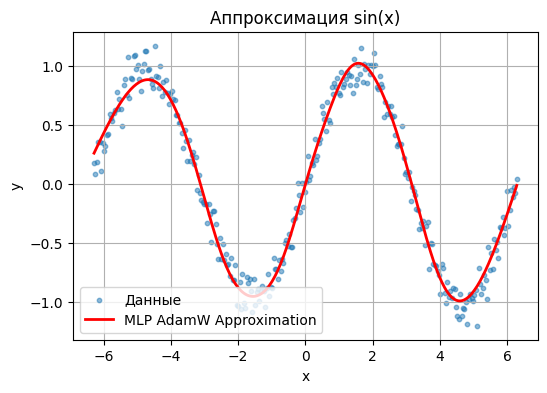

In [7]:
# Что нужно сделать

# AdamW сочетает Adam с decoupled weight decay:
# сначала уменьшаем веса по L2 ($w \leftarrow w − \eta \cdot \lambda \cdot w$),
# потом выполняем стандартный шаг Adam по скорректированным моментам.
# Реализуйте метод update_adamw в вашем классе.

import matplotlib.pyplot as plt
import numpy as np

np.random.seed(0)


class MLP:
    def __init__(self, layer_sizes, activation="tanh"):
        self.eps = 1e-8  # Маленькая константа для избежания деления на ноль
        self.weight_decay = 1e-4  # Decoupled weight decay
        # Счётчик итераций для Adam
        # Ваш код здесь
        self.iterations = 0
        self.layer_sizes = layer_sizes
        self.activation = activation
        self.W, self.b = [], []
        self.Z_list, self.A_list = [], []
        self.dW_list, self.db_list = [], []
        # Добавим накопители моментов
        # Ваш код здесь
        self.mW, self.vW, self.mb, self.vb = [], [], [], []
        # Добавим параметры Adam beta1, beta2
        # Ваш код здесь
        self.beta1 = 0.9
        self.beta2 = 0.999

        for i in range(len(layer_sizes) - 1):
            in_dim, out_dim = layer_sizes[i], layer_sizes[i + 1]
            self.W.append(
                np.random.randn(in_dim, out_dim) * np.sqrt(2 / (in_dim + out_dim))
            )
            self.b.append(np.zeros((1, out_dim)))
            # Инициализация накопителей
            # Ваш код здесь
            self.mW.append(np.zeros((in_dim, out_dim)))
            self.vW.append(np.zeros((in_dim, out_dim)))
            self.mb.append(np.zeros((1, out_dim)))
            self.vb.append(np.zeros((1, out_dim)))

    def _activate(self, Z):
        if self.activation == "sigmoid":
            return 1 / (1 + np.exp(-Z))
        elif self.activation == "relu":
            return np.maximum(0, Z)
        elif self.activation == "tanh":
            return np.tanh(Z)
        else:
            raise ValueError(self.activation)

    def _dactivate(self, Z):
        if self.activation == "sigmoid":
            s = 1 / (1 + np.exp(-Z))
            return s * (1 - s)
        elif self.activation == "relu":
            return (Z > 0).astype(float)
        elif self.activation == "tanh":
            return 1 - np.tanh(Z) ** 2

    def forward(self, X):
        self.Z_list, self.A_list = [], []
        A = X
        self.A_list.append(A)
        for i in range(len(self.W)):
            Z = A.dot(self.W[i]) + self.b[i]
            self.Z_list.append(Z)
            A = self._activate(Z) if i < len(self.W) - 1 else Z
            self.A_list.append(A)
        return A

    def mse(self, y_pred, y_true):
        return np.mean((y_pred - y_true) ** 2)

    def backward(self, y_true):
        m = y_true.shape[0]
        # Выходной слой (линейная активация, производная = 1)
        aL, zL = self.A_list[-1], self.Z_list[-1]
        delta = 2 * (aL - y_true) / m
        # Градиенты выхода
        a_prev = self.A_list[-2]
        dW = a_prev.T.dot(delta)
        db = np.sum(delta, axis=0, keepdims=True)
        self.dW_list, self.db_list = [dW], [db]
        # Скрытые слои (используем производную активации)
        for l in range(len(self.layer_sizes) - 2, 0, -1):
            z = self.Z_list[l - 1]
            a_prev = self.A_list[l - 1]
            W_next = self.W[l]
            delta = delta.dot(W_next.T) * self._dactivate(z)
            dW = a_prev.T.dot(delta)
            db = np.sum(delta, axis=0, keepdims=True)
            self.dW_list.insert(0, dW)
            self.db_list.insert(0, db)

    def update_adamw(self, lr):
        self.iterations += 1
        for i in range(len(self.W)):
            # decoupled weight decay: уменьшаем веса по направлению к нулю
            self.W[i] -= self.weight_decay * lr * self.W[i]
            # обновление моментов как в Adam
            self.mW[i] = self.beta1 * self.mW[i] + (1 - self.beta1) * self.dW_list[i]
            self.vW[i] = self.beta2 * self.vW[i] + (1 - self.beta2) * (
                self.dW_list[i] ** 2
            )
            self.mb[i] = self.beta1 * self.mb[i] + (1 - self.beta1) * self.db_list[i]
            self.vb[i] = self.beta2 * self.vb[i] + (1 - self.beta2) * (
                self.db_list[i] ** 2
            )
            # корректировка
            mW_hat = self.mW[i] / (1 - self.beta1**self.iterations)
            vW_hat = self.vW[i] / (1 - self.beta2**self.iterations)
            mb_hat = self.mb[i] / (1 - self.beta1**self.iterations)
            vb_hat = self.vb[i] / (1 - self.beta2**self.iterations)
            # обновляем параметры
            self.W[i] -= lr * mW_hat / (np.sqrt(vW_hat) + self.eps)
            self.b[i] -= lr * mb_hat / (np.sqrt(vb_hat) + self.eps)


# Разбиваем на train/val
perm = np.random.permutation(len(X))
split = int(0.8 * len(X))
X_train, y_train = X[perm[:split]], y[perm[:split]]
X_val, y_val = X[perm[split:]], y[perm[split:]]

# Инициализация модели
mlp = MLP([1, 50, 1], activation="tanh")

# Параметры обучения и Reduce on Plateau
initial_lr = 0.01
lr = initial_lr
patience = 20
best_val_loss = np.inf
wait = 0
epochs = 500

train_loss_history = []
val_loss_history = []

for epoch in range(1, epochs + 1):
    # тренировка на всём train
    preds_train = mlp.forward(X_train)
    train_loss = mlp.mse(preds_train, y_train)
    train_loss_history.append(train_loss)

    mlp.backward(y_train)
    # Ваш код здесь
    mlp.update_adamw(lr)

    # оценка на валидации
    preds_val = mlp.forward(X_val)
    val_loss = mlp.mse(preds_val, y_val)
    val_loss_history.append(val_loss)

    #  Reduce on Plateau
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        wait = 0
    else:
        wait += 1
        if wait >= patience:
            lr *= 0.5
            wait = 0
            print(f"Epoch {epoch}: val_loss plateaued, new lr = {lr:.5f}")

    if epoch % 200 == 0:
        print(
            f"Epoch {epoch}: train_loss={train_loss:.4f}, val_loss={val_loss:.4f}, lr={lr:.5f}"
        )

# График финальной аппроксимации
preds_all = mlp.forward(X)
idx = np.argsort(X.flatten())
plt.figure(figsize=(6, 4))
plt.scatter(X, y, s=10, alpha=0.5, label="Данные")
plt.plot(
    X.flatten()[idx],
    preds_all.flatten()[idx],
    color="red",
    linewidth=2,
    label="MLP AdamW Approximation",
)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Аппроксимация sin(x)")
plt.legend()
plt.grid(True)
plt.show()